In [1]:
import sys 
sys.path.append('../src')

from data_processing.load import load_and_preprocess_data

from data_processing.utils import load_checkpoint, save_checkpoint, run_inference_bnn, run_svi
from models.model import model, model_mw_gamma, model_cf_logitnormal

import jax
import jax.numpy as jnp
import numpy as np
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
from jax import random
import time
from numpyro.infer import MCMC, NUTS, Predictive, SVI, Trace_ELBO
import arviz as az
import scipy
from scipy.stats import percentileofscore
from numpyro.infer.autoguide import AutoNormal, AutoDiagonalNormal
from numpyro.optim import Adam



In [2]:
jax.config.update('jax_num_cpu_devices', 6) # I have 8 physical cores

### Load data and preprocess
- wind direction transformed from degree using sin and cos
- select one bid zone
- include UMM downtime data
- calculate capacity factor
- scale input features and meta data

Shapes:
- X: (timestamps, wind parks, features)
- Y: (timestamps)
- sites_meta: (wind parks, 1)

In [3]:
from operator import itemgetter
data = load_and_preprocess_data()
(X_train, X_test, Y_train_gen, Y_test_gen,
 Y_train_cf, Y_test_cf, Y_train_aval, Y_test_aval,
 sites_meta, feature_cols) = itemgetter(
    "X_train","X_test","Y_train_gen","Y_test_gen",
    "Y_train_cf","Y_test_cf","Y_train_aval","Y_test_aval",
    "sites_meta","feature_cols"
)(data)


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:60: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_train shape: (19130, 6, 6)
Preprocessing done. X_test shape: (2161, 6, 6)


### Simple BNN
input: (timestamps, wind parks, features)
output: (timestamps)


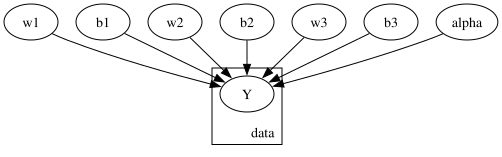

In [4]:
import numpyro
numpyro.render_model(
    model,
    model_args=(X_test,),
)

In [ ]:
args = {
    'num_warmup': 40,
    'num_samples': 60,
    'num_chains': 5,
}
# args = dict(
#     num_warmup=50,
#     num_samples=100,
#     num_chains=1,
# )

rng_key, rng_key_predict = random.split(random.PRNGKey(0))

Run MCMC

In [ ]:
# simple BNN, but already with Gamma distribution, without softplus, bounded below at 0
samples = run_inference_bnn(model, args, rng_key, X_train, Y_train_gen)

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     alpha      1.89      0.17      1.87      1.74      2.18      3.08      3.17
     b1[0]      0.46      1.03      0.77     -1.17      1.94      2.57     12.67
     b1[1]     -0.54      1.17     -0.67     -1.66      1.75      2.55     11.79
     b1[2]      0.50      1.40      0.84     -2.13      1.98      2.54     21.74
     b1[3]      0.35      1.34      0.08     -0.98      2.86      2.53     24.05
     b1[4]      0.61      0.80      0.27     -0.24      2.07      2.61     10.05
     b1[5]      0.43      0.54      0.41     -0.35      1.33      2.56     11.21
     b1[6]     -0.03      1.20      0.45     -1.80      1.36      2.53     23.71
     b1[7]      1.20      1.37      1.38     -0.86      3.39      2.54     15.54
     b1[8]     -0.11      1.18     -0.06     -2.18      1.22      2.65      7.48
     b1[9]     -0.19      1.69     -0.77     -2.06      2.16      2.52     36.32
    b1[10]      0.58      1

In [7]:
preds_MCMC = Predictive(model, samples)(rng_key_predict, X_test)['Y']

In [ ]:
# Gamma distribution and softplus, seperate mu and k, bounded below at 0
samples_gamma = run_inference_bnn(model_mw_gamma, args, rng_key, X_train, Y_train_gen)


sample: 100%|██████████| 150/150 [11:15<00:00,  4.50s/it, 1023 steps of size 5.74e-03. acc. prob=0.93]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     b1[0]      1.56      0.30      1.66      1.06      1.91      5.05      1.26
     b1[1]     -0.68      0.59     -0.39     -1.54     -0.10      3.73      1.69
     b1[2]      0.10      0.19      0.05     -0.14      0.41      7.67      1.02
     b1[3]     -0.03      0.15     -0.01     -0.21      0.13     11.53      1.08
     b1[4]     -0.86      0.68     -0.50     -2.20     -0.24      3.59      1.72
     b1[5]      0.22      0.20      0.21     -0.08      0.52      6.33      1.24
     b1[6]     -2.18      0.24     -2.22     -2.59     -1.79     14.36      1.02
     b1[7]     -1.28      0.14     -1.26     -1.48     -1.04     14.51      1.03
     b1[8]     -0.47      0.17     -0.46     -0.73     -0.23      3.90      1.93
     b1[9]      1.24      0.16      1.20      1.00      1.47     24.07      1.02
    b1[10]      1.78      0.41      1.85      1.48      2.28     10.25      0.99
    b1[11]      0.04      0

In [34]:
preds_MCMC_mw_gamma = Predictive(model_mw_gamma, samples_gamma)(rng_key_predict, X_test)['Y']

In [ ]:
# Logit Normal, bounded between 0 and 1
samples_logitnormal = run_inference_bnn(model_cf_logitnormal, args, rng_key, X_train, Y_train_cf)

sample: 100%|██████████| 150/150 [10:55<00:00,  4.37s/it, 1023 steps of size 1.44e-03. acc. prob=0.94]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     b1[0]      0.45      0.15      0.48      0.30      0.64     11.13      0.99
     b1[1]      1.56      0.11      1.58      1.37      1.70      7.20      1.14
     b1[2]      1.61      0.18      1.60      1.29      1.92      4.49      1.64
     b1[3]     -0.02      0.27      0.02     -0.42      0.34      2.89      2.46
     b1[4]     -1.44      0.12     -1.46     -1.60     -1.29      5.10      1.16
     b1[5]      0.02      0.10      0.01     -0.13      0.16      4.31      1.82
     b1[6]      0.44      0.24      0.49      0.18      0.67      8.18      1.01
     b1[7]     -1.86      0.19     -1.91     -2.13     -1.54      4.91      1.34
     b1[8]     -1.00      0.32     -1.13     -1.27     -0.37      5.52      1.33
     b1[9]     -0.31      0.21     -0.34     -0.51      0.13     11.33      1.03
    b1[10]     -1.18      0.14     -1.21     -1.34     -1.03     14.19      1.05
    b1[11]      1.52      0

In [27]:
preds_MCMC_cf_lgit = jax.nn.sigmoid(Predictive(model_cf_logitnormal, samples_logitnormal)(rng_key_predict, X_test)['y_star'])

In [ ]:
# X_small = X_train[:100]
# Y_small = Y_train_cf[:100]

# samples_logit_small = run_inference_bnn(model_cf_logitnormal, args, rng_key, X_small, Y_small)

sample: 100%|██████████| 150/150 [00:12<00:00, 12.13it/s, 1023 steps of size 1.56e-03. acc. prob=0.84]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     b1[0]     -0.12      0.39     -0.28     -0.62      0.50      7.87      1.14
     b1[1]      0.44      0.37      0.45     -0.15      1.03     15.46      1.02
     b1[2]     -0.02      0.38     -0.06     -0.56      0.61      8.81      0.99
     b1[3]     -0.81      0.22     -0.82     -1.18     -0.50     13.02      1.24
     b1[4]      0.03      0.54      0.03     -1.07      0.66     18.81      0.99
     b1[5]      0.50      0.33      0.48      0.05      1.07      9.32      1.02
     b1[6]      0.06      0.52      0.15     -0.85      0.64      6.26      1.11
     b1[7]      0.19      0.48      0.25     -0.64      0.99     15.05      1.16
     b1[8]     -0.08      0.33     -0.18     -0.56      0.54      7.59      1.12
     b1[9]     -0.32      0.46     -0.28     -1.02      0.47     22.28      1.02
    b1[10]      0.08      0.38      0.14     -0.49      0.64      5.95      1.28
    b1[11]     -0.17      0

In [32]:
save_checkpoint(samples_logitnormal, "model_cf_logitnormal", args, rng_key, target="cf")

Saved checkpoint for model 'model_cf_logitnormal': ../../checkpoints/model_cf_logitnormal_2025-10-28_14-58-21_cf.pkl


'../../checkpoints/model_cf_logitnormal_2025-10-28_14-58-21_cf.pkl'

Load checkpoint (MCMC)

In [ ]:
state_ckp = load_checkpoint(file_name='model_2025-10-23_09-03-57_gen') # model_2025-10-21_14-28-15_gen, model_2025-10-23_09-03-57_gen
samples_ckp = state_ckp['samples']
args_ckp = state_ckp['args']
rng_key_ckp = state_ckp['rng_key']
rng_key_ckp, rng_key_predict_ckp = random.split(rng_key_ckp)

In [119]:
preds_MCMC_ckp = Predictive(model, samples_ckp)(rng_key_predict_ckp, X_test)['Y']

Run VI

In [45]:
guide = AutoDiagonalNormal(model_cf_logitnormal)
svi_result = run_svi(model_cf_logitnormal, guide, rng_key, X_train, Y_train_cf, num_steps=5000, lr=1e-4)
params = svi_result.params
preds_VI = jax.nn.sigmoid(Predictive(model_cf_logitnormal, guide=guide, params=params, num_samples=500)(rng_key_predict, X_test)['y_star'])


Final ELBO loss: 3308700416.000


### Evaluation

In [61]:
preds = preds_MCMC_mw_gamma
# CF: preds_MCMC and preds_VI
# Gen: preds_MCMC_ckp


In [62]:
preds_mean = preds.mean(axis=0)

# Percentiles, no assumption about shape of distribution, central 95% interval
# 95% of samples fall here
percentiles = np.percentile(preds, [2.5, 97.5], axis=0)
median = np.percentile(preds, 50, axis=0)

# Assumes posterior is Normal, symmetric around mean,
# If it's normal, 95% if samples fall here
preds_std = preds.std(axis=0)
normal_lower = preds_mean - 1.96 * preds_std
normal_upper = preds_mean + 1.96 * preds_std

# HDI (high densitiy interval), narrowest possible interval 
# Most probable 95% region
hdi = az.hdi(np.expand_dims(preds, axis=0), hdi_prob=0.95)

# Widths of different intervals (90% CI)
hdi_avg_width = (hdi[:,1]-hdi[:,0]).mean()
percentile_avg_width = (percentiles[1]-percentiles[0]).mean()
normal_ci_avg_width = (normal_upper - normal_lower).mean()

print(f"Percentile width: {percentile_avg_width}")
print(f"HDI width: {hdi_avg_width}")
print(f"Normal width: {normal_ci_avg_width}")

inside = (Y_test_gen >= percentiles[0]) & (Y_test_gen <= percentiles[1])
coverage_90 = inside.mean()
print(f"\nEmpirical coverage (0.025–0.975): {coverage_90:.3f}")

below_median = (Y_test_gen <= median).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")


Percentile width: 216.47441437780168
HDI width: 207.60256327429016
Normal width: 229.5724334716797

Empirical coverage (0.025–0.975): 0.906
Below median (should be ~0.5): 0.374


In [63]:
rmse = jnp.sqrt(jnp.mean((preds_mean - Y_test_gen) ** 2))
print("Test RMSE (gen prediction):", rmse)

Test RMSE (gen prediction): 69.55823


In [59]:
rmse = jnp.sqrt(jnp.mean((preds_mean * Y_test_aval - Y_test_gen) ** 2))
print("Test RMSE (cf prediction):", rmse)

Test RMSE (cf prediction): 70.511856


Empirical coverage of percentiles

### Plots

Variational Inference loss

Final ELBO loss: 3308700416.000


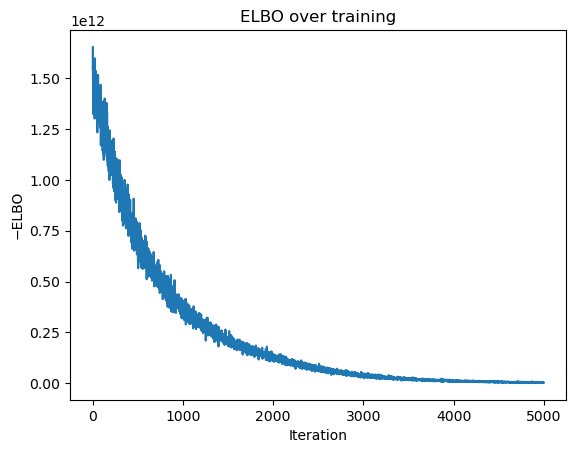

In [54]:
losses = svi_result.losses
print(f"Final ELBO loss: {losses[-1]:.3f}")
plt.plot(losses)
plt.title("ELBO over training")
plt.xlabel("Iteration")
plt.ylabel("−ELBO")
plt.show()


Residuals on training dataset

In [145]:
# positive residuals correspond to missed peaks
# positive tail: in general more underpredictions (train data)
pred_train_mcmc = Predictive(model, samples_ckp)(rng_key_predict_ckp, X_train)['Y']
#pred_train_vi = Predictive(model, guide=guide, params=params, num_samples=500)(rng_key_predict, X_train)['Y']


In [146]:

pred_train = pred_train_mcmc # or pred_train_mcmc


skew: 0.84045607


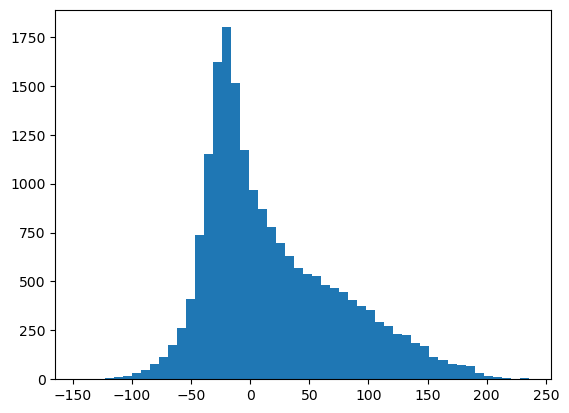

In [147]:
yhat = jnp.mean(pred_train, axis=0)
resid = Y_train_gen - yhat
print("skew:", scipy.stats.skew(np.array(resid)))
plt.hist(np.array(resid), bins=50); plt.show()



Different intervals (percentile vs. hdi vs. normal)

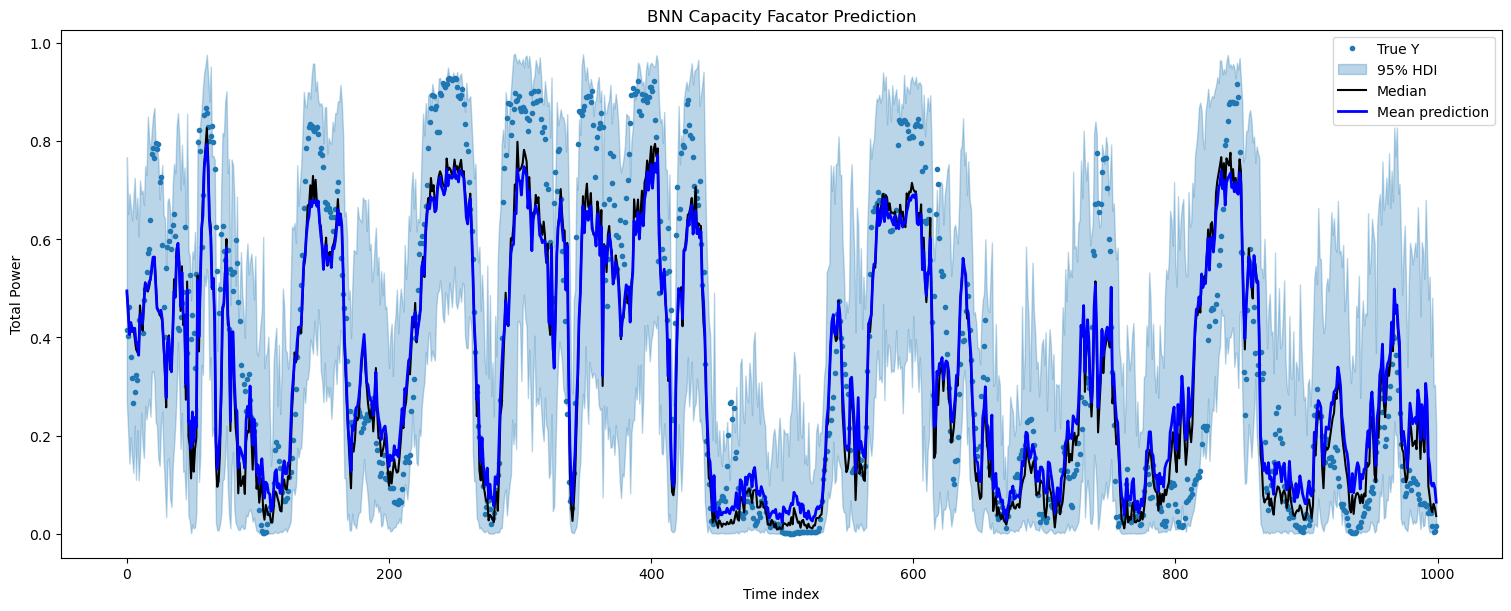

In [60]:
# Plot 90% CI
n_plot = 1000
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(Y_test_cf[:n_plot], ".", label="True Y")
#ax.fill_between(np.arange(n_plot), normal_lower[:n_plot], normal_upper[:n_plot], label='Normal 95% CI', color="green", alpha=0.5)
ax.fill_between(np.arange(n_plot), hdi[:n_plot, 0], hdi[:n_plot, 1], color="C0", label="95% HDI", alpha=.3)
#ax.fill_between(np.arange(n_plot), percentiles[0, :n_plot], percentiles[1, :n_plot], label="Percentile 95% CI", color="lightblue", alpha=0.7)
ax.plot(median[:n_plot], label="Median", color="black")
ax.plot(preds_mean[:n_plot], "b", lw=2, label="Mean prediction")
ax.set(xlabel="Time index", ylabel="Total Power", title="BNN Capacity Facator Prediction")
ax.legend()
plt.show()


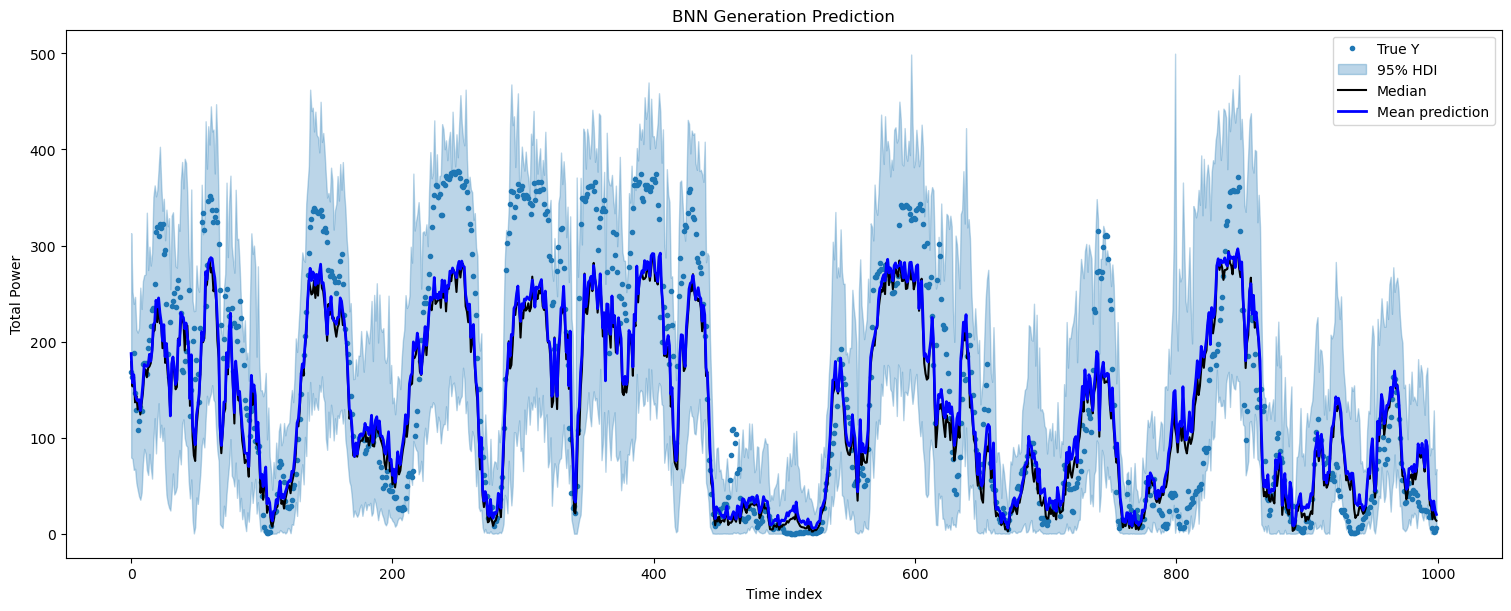

In [64]:
# Plot 90% CI
n_plot = 1000
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(Y_test_gen[:n_plot], ".", label="True Y")
#ax.fill_between(np.arange(n_plot), normal_lower[:n_plot], normal_upper[:n_plot], label='Normal 95% CI', color="green", alpha=0.5)
ax.fill_between(np.arange(n_plot), hdi[:n_plot, 0], hdi[:n_plot, 1], color="C0", label="95% HDI", alpha=.3)
#ax.fill_between(np.arange(n_plot), percentiles[0, :n_plot], percentiles[1, :n_plot], label="Percentile 95% CI", color="lightblue", alpha=0.7)
ax.plot(median[:n_plot], label="Median", color="black")
ax.plot(preds_mean[:n_plot], "b", lw=2, label="Mean prediction")
ax.set(xlabel="Time index", ylabel="Total Power", title="BNN Generation Prediction")
ax.legend()
plt.show()


Stacked HDI

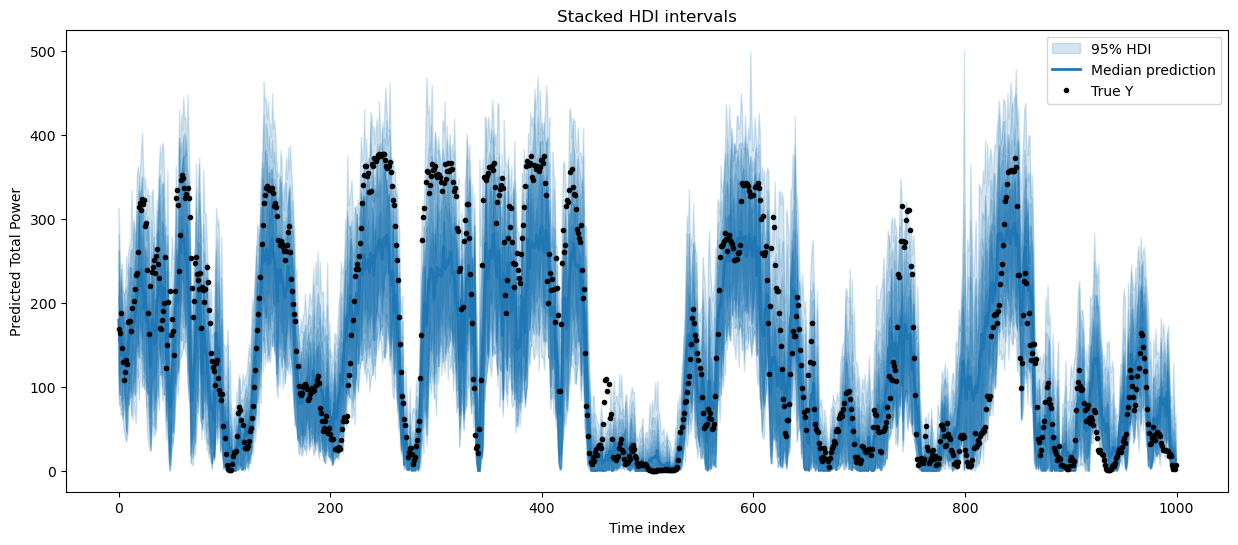

In [65]:
# Only plot first n_plot timesteps
n_plot = 1000

# Compute multiple HDI levels
hdi_probs = np.arange(0.05, 1.0, 0.05)
preds_hdi = np.expand_dims(preds, axis=0)
hdis = {float(p): az.hdi(preds_hdi, hdi_prob=float(p)) for p in hdi_probs}

X_new = np.arange(n_plot)
median = np.percentile(preds, 50, axis=0)

plt.figure(figsize=(15, 6))
max_p = max(hdis.keys())
for p in hdi_probs:
    hdi = hdis[p][:n_plot]
    alpha = 0.2 * float(p)
    label = f'{int(p*100)}% HDI' if p == max_p else None
    plt.fill_between(X_new, hdi[:, 0], hdi[:, 1], color='C0', alpha=alpha, label=label)

plt.plot(X_new, median[:n_plot], color='C0', lw=2, label='Median prediction')
plt.plot(Y_test_gen[:n_plot], ".", color="black", label="True Y")
plt.title("Stacked HDI intervals")
plt.xlabel("Time index")
plt.ylabel("Predicted Total Power")
plt.legend()
plt.show()


Std noise of model samples

<Axes: title={'center': 'std noise'}>

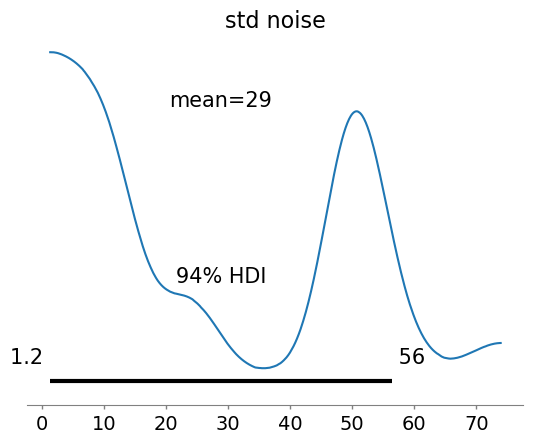

In [65]:
# Plot std noise
az.plot_posterior({'std noise': 1.0 / jnp.sqrt(samples['prec_obs'])})

PIT (Probability Integral Transform)
- Checks calibration of probabilistic forecasts
- Model well-calibrated -> values uniformly distributed
- For each observation $y_i$:
    - Take all model’s predictive samples for that data point
    - Compute how many of those samples are less than or equal to the actual observed value
    - PIT value $u_i = P_{\hat{Y_i}}​​(Y\leq y)$
    - with MCMC: $u_i \approx \frac{1}{S} \sum_{s=1}^S 1[y_i^{(s)}\leq y_i]$

PIT mean: 0.7161846367422491 (should be uniform if calibrated)


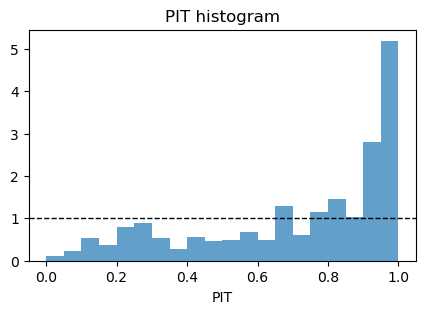

In [66]:
pits = np.array([percentileofscore(preds[:, t], Y_test_gen[t], kind='mean') / 100.0 for t in range(preds.shape[1])])
pits_mean = pits.mean()
print(f"PIT mean: {pits_mean} (should be uniform if calibrated)")

plt.figure(figsize=(5,3))
plt.hist(pits, bins=20, range=(0,1), density=True, alpha=0.7)
plt.axhline(1.0, color='k', ls='--', lw=1)  # reference
plt.xlabel("PIT")
plt.title("PIT histogram")
plt.show()